In [1]:
import numpy as np
import matplotlib.pyplot

In [2]:
def cal_pop_fitness(equation_inputs, pop):
    """Calculates the fitness value of each solution in the current population.

    The fitness function calculates the sum of the products between each input and its corresponding weight.

    Args:
        equation_inputs (list): The inputs to the equation.
        pop (np.ndarray): The current population.

    Returns:
        np.ndarray: The fitness of each individual in the population.
    """
    fitness = np.sum(pop*equation_inputs, axis=1)
    return fitness

In [3]:
def select_mating_pool(pop, fitness, num_parents):
    """Selects the best individuals in the current generation as parents for producing the offspring of the next generation.

    Args:
        pop (np.ndarray): The current population.
        fitness (np.ndarray): The fitness of each individual in the population.
        num_parents (int): The number of parents to select.

    Returns:
        np.ndarray: The selected parents.
    """
    # Shift fitness values to be non-negative
    fitness = fitness - fitness.min()  # Ensures all fitness values are non-negative

    # Select parents using random choice weighted by fitness
    parents_idx = np.random.choice(pop.shape[0], size=num_parents, replace=False, p=fitness / fitness.sum())
    return pop[parents_idx]

In [4]:
def crossover(parents, offspring_size):
    """Performs crossover between two parents to create offspring.

    Args:
        parents (np.ndarray): The selected parents for mating.
        offspring_size (tuple): The size of the offspring array.

    Returns:
        np.ndarray: The offspring generated after crossover.
    """
    offspring = np.empty(offspring_size)
    # The point at which crossover takes place between two parents. Usually, it is at the center.
    crossover_point = np.uint8(offspring_size[1]/2)

    for k in range(offspring_size[0]):
        # Index of the first parent to mate.
        parent1_idx = k%parents.shape[0]
        # Index of the second parent to mate.
        parent2_idx = (k+1)%parents.shape[0]
        # The new offspring will have its first half of its genes taken from the first parent.
        offspring[k, 0:crossover_point] = parents[parent1_idx, 0:crossover_point]
        # The new offspring will have its second half of its genes taken from the second parent.
        offspring[k, crossover_point:] = parents[parent2_idx, crossover_point:]
    return offspring

In [5]:
def mutation(offspring_crossover, num_mutations=1):
    num_genes = offspring_crossover.shape[1]
    for idx in range(offspring_crossover.shape[0]):
        gene_indices = np.random.choice(num_genes, size=num_mutations, replace=False)
        for gene_idx in gene_indices:
            random_value = np.random.uniform(-1.0, 1.0)
            offspring_crossover[idx, gene_idx] = np.clip(
                offspring_crossover[idx, gene_idx] + random_value, -4.0, 4.0
            )
    return offspring_crossover

In [6]:
"""
Genetic Algorithm to maximize the equation:
y = w1x1 + w2x2 + w3x3 + w4x4 + w5x5 + w6x6
where (x1, x2, x3, x4, x5, x6) = (3, -1, 4.5, 6, -10, -5.7)

This script uses a genetic algorithm to find the best values for the six weights (w1 to w6) that maximize the equation.
"""

# Inputs to the equation
equation_inputs = [3, -1, 4.5, 6, -10, -5.7]

# Number of weights to be optimized
num_weights = len(equation_inputs)

"""
Genetic Algorithm Parameters:
- Mating pool size
- Population size
"""
sol_per_pop = 30  # Number of solutions (chromosomes) per population
num_parents_mating = 4  # Number of parents selected for mating

# Defining the population size
pop_size = (sol_per_pop, num_weights)  # The population will have sol_per_pop chromosomes where each chromosome has num_weights genes.

# Creating the initial population
new_population = np.random.uniform(low=-4.0, high=4.0, size=pop_size)
print(new_population)

[[ 0.97429379  0.37240753  1.24595616  0.72679234  2.34936031  0.87167583]
 [ 3.82543913  0.07843091 -0.48572287 -1.36503383  3.5620775  -0.39498701]
 [-0.99944803 -3.11122267  1.52994389  0.53188763 -2.06715209 -2.6946155 ]
 [-2.4107938  -3.96406762 -0.57573936  2.35388546 -1.63647253  3.01271189]
 [-2.0003998   1.45732845  1.37211711 -1.99951404  0.6942072   3.69800112]
 [-3.11432224 -2.57334598 -1.44101382  2.51851127 -3.78687189  1.46607787]
 [ 0.19325138 -0.93697208 -1.84523477 -3.08460208  2.49259241 -0.92965188]
 [-0.35802889 -1.98048991  0.60642971  0.56044761  3.35091289  1.12453692]
 [ 0.61362781  3.66401932 -1.50414057  0.1490456   1.13277636 -2.56196246]
 [-2.02007788 -2.49585266 -1.10041759 -1.00062641 -1.92231386 -2.54073774]
 [-0.10333766  3.82466472  0.96743826  2.17553592 -0.6666362   2.07296283]
 [-1.99882691 -2.85087823 -2.96228646  2.9673804  -0.29117861 -0.96216216]
 [-2.33091251  2.01094903  3.67300238 -0.16706382  0.60468605 -2.77361148]
 [-0.16712676  1.98897709

In [7]:
best_outputs = []
num_generations = 100

for generation in range(num_generations):
    print("Generation : ", generation)
    # Measuring the fitness of each chromosome in the population.
    fitness = cal_pop_fitness(equation_inputs, new_population)
    print("Fitness")
    print(fitness)

    best_outputs.append(np.max(np.sum(new_population * equation_inputs, axis=1)))
    # The best result in the current iteration.
    print("Best result : ", np.max(np.sum(new_population * equation_inputs, axis=1)))

    # Selecting the best parents in the population for mating.
    parents = select_mating_pool(new_population, fitness, num_parents_mating)
    print("Parents")
    print(parents)

    # Generating next generation using crossover.
    offspring_crossover = crossover(parents, offspring_size=(pop_size[0] - parents.shape[0], num_weights))
    print("Crossover")
    print(offspring_crossover)

    # Adding some variations to the offspring using mutation.
    offspring_mutation = mutation(offspring_crossover, num_mutations=3)
    print("Mutation")
    print(offspring_mutation)

    # Creating the new population based on the parents and offspring.
    new_population[0:parents.shape[0], :] = parents
    new_population[parents.shape[0]:, :] = offspring_mutation

Streaming output truncated to the last 5000 lines.
 [ 2.75344594 -0.1485277   3.65951309  4.         -3.54609884 -2.97709538]
 [ 2.17354271 -1.46609904  3.04032936  3.64241784 -3.6585509  -3.59950077]
 [ 2.39352182 -0.1485277   4.          4.         -4.         -2.97709538]
 [ 1.50291954 -0.67959378  3.04032936  4.         -3.92210419 -3.59950077]
 [ 2.75344594 -0.1485277   3.65951309  4.         -3.54609884 -2.97709538]
 [ 2.17354271 -1.46609904  3.04032936  3.64241784 -3.6585509  -3.59950077]
 [ 2.39352182 -0.1485277   4.          4.         -4.         -2.97709538]
 [ 1.50291954 -0.67959378  3.04032936  4.         -3.92210419 -3.59950077]
 [ 2.75344594 -0.1485277   3.65951309  4.         -3.54609884 -2.97709538]
 [ 2.17354271 -1.46609904  3.04032936  3.64241784 -3.6585509  -3.59950077]
 [ 2.39352182 -0.1485277   4.          4.         -4.         -2.97709538]
 [ 1.50291954 -0.67959378  3.04032936  4.         -3.92210419 -3.59950077]
 [ 2.75344594 -0.1485277   3.65951309  4.        

In [8]:
# Getting the best solution after iterating finishing all generations.
# At first, the fitness is calculated for each solution in the final generation.
fitness = cal_pop_fitness(equation_inputs, new_population)
# Then return the index of that solution corresponding to the best fitness.
best_match_idx = np.where(fitness == np.max(fitness))

print("Best solution : ", new_population[best_match_idx, :])
print("Best solution fitness : ", fitness[best_match_idx])

Best solution :  [[[ 3.13945403 -1.70404283  3.8775133   4.         -4.
   -4.        ]]]
Best solution fitness :  [115.37121478]


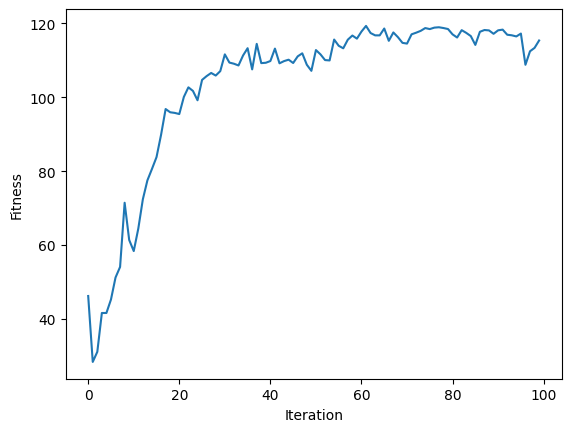

In [9]:
# Plotting the best outputs over generations
matplotlib.pyplot.plot(best_outputs)
matplotlib.pyplot.xlabel("Iteration")
matplotlib.pyplot.ylabel("Fitness")
matplotlib.pyplot.show()

In [10]:
import matplotlib.pyplot as plt

# Runs one complete GA and returns the best fitness of every generation
def run_ga(num_mutations=3, num_parents=4, num_generations=100, seed=None):
    if seed is not None:
        np.random.seed(seed)
    population = np.random.uniform(low=-4.0, high=4.0, size=pop_size)
    history = []
    for _ in range(num_generations):
        fitness = cal_pop_fitness(equation_inputs, population)
        history.append(np.max(fitness))
        parents = select_mating_pool(population, fitness, num_parents)
        offspring = crossover(parents, offspring_size=(pop_size[0] - parents.shape[0], num_weights))
        offspring = mutation(offspring, num_mutations=num_mutations)
        population[0:parents.shape[0], :] = parents
        population[parents.shape[0]:, :] = offspring
    final_best = np.max(cal_pop_fitness(equation_inputs, population))
    return np.array(history), final_best

num_mutations = 1: final fitness 116.63 +/- 4.55 (96.5% of max)
num_mutations = 3: final fitness 117.15 +/- 2.77 (97.0% of max)
num_mutations = 5: final fitness 113.10 +/- 2.72 (93.6% of max)


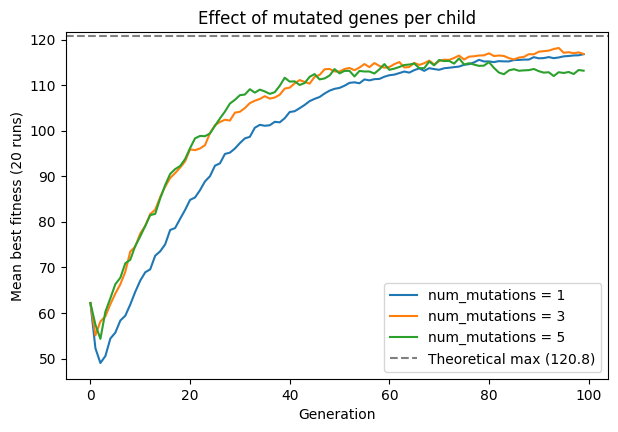

num_parents = 2: final fitness 112.02 +/- 8.45 (92.7% of max)
num_parents = 4: final fitness 117.15 +/- 2.77 (97.0% of max)
num_parents = 8: final fitness 119.27 +/- 1.45 (98.7% of max)


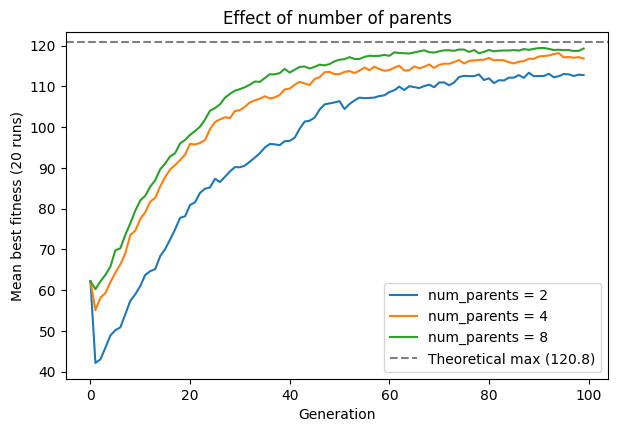

In [11]:
def run_experiment(param_name, values, title, n_runs=20):
    plt.figure(figsize=(7, 4.5))
    for v in values:
        curves, finals = [], []
        for seed in range(n_runs):
            history, final_best = run_ga(seed=seed, **{param_name: v})
            curves.append(history)
            finals.append(final_best)
        finals = np.array(finals)
        plt.plot(np.mean(curves, axis=0), label=f'{param_name} = {v}')
        print(f'{param_name} = {v}: final fitness {finals.mean():.2f} +/- {finals.std():.2f} '
              f'({finals.mean() / 120.8 * 100:.1f}% of max)')
    plt.axhline(120.8, linestyle='--', color='gray', label='Theoretical max (120.8)')
    plt.xlabel('Generation')
    plt.ylabel(f'Mean best fitness ({n_runs} runs)')
    plt.title(title)
    plt.legend()
    plt.show()

run_experiment('num_mutations', [1, 3, 5], 'Effect of mutated genes per child')
run_experiment('num_parents', [2, 4, 8], 'Effect of number of parents')